# SaaSquatch Platform: API Walkthrough

This notebook calls the **SaaSquatch backend API** step by step. It covers:

1. Checking the API is up and whether live AI (OpenAI `gpt-4o-mini`) is configured
2. Enriching a batch of raw leads with `POST /api/enrich-leads`
3. Reading the enriched output: AI readiness score, acquisition fit, growth bottlenecks, AI transformation angle
4. Filtering and ranking leads, as the dashboard does
5. How the API handles bad input and AI failures (per-lead fallback)

**Before running:** start the backend from the repo root with `npm run dev` (or `npm run dev:backend`).
The API listens on `http://localhost:4000` by default. Set the `SAASQUATCH_API_URL` environment variable to point elsewhere.

In [1]:
import os
import json
import time

import requests
import pandas as pd
import matplotlib.pyplot as plt

API_URL = os.environ.get("SAASQUATCH_API_URL", "http://localhost:4000").rstrip("/")
TIMEOUT = 120  # seconds; enrichment makes one OpenAI call per lead

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

def show(resp):
    """Print status code and pretty JSON body of a response."""
    print(f"HTTP {resp.status_code}")
    try:
        print(json.dumps(resp.json(), indent=2))
    except ValueError:
        print(resp.text)

print("API base URL:", API_URL)

API base URL: http://localhost:4000


## 1. Health check

`GET /api/health` reports whether the server is up and whether an `OPENAI_API_KEY` is configured.
`aiEnabled: false` means every lead will be scored by the built-in heuristic fallback.

In [2]:
health = requests.get(f"{API_URL}/api/health", timeout=10)
show(health)
assert health.ok, "Backend is not reachable. Start it with `npm run dev` from the repo root."

HTTP 200
{
  "status": "ok",
  "aiEnabled": true,
  "model": "gpt-4o-mini",
  "timestamp": "2026-10-06T18:37:03.006Z"
}


## 2. Prepare raw leads

The endpoint accepts a JSON **array** of leads, or an object `{ "leads": [...] }`.
Only `companyName` is required. Every other field is optional context that improves the analysis.
These are the same fictional companies the dashboard ships with.

In [3]:
raw_leads = [
    {"id": "lead-001", "companyName": "Ledgerly", "industry": "Fintech SaaS", "employeeCount": 85,
     "annualRevenue": "$8M ARR", "location": "Austin, TX", "website": "https://ledgerly.example.com",
     "description": "Accounts-payable automation platform for mid-market finance teams with a manual invoice review workflow."},
    {"id": "lead-002", "companyName": "ShiftPilot", "industry": "HR Tech", "employeeCount": 42,
     "annualRevenue": "$3.2M ARR", "location": "Denver, CO", "website": "https://shiftpilot.example.com",
     "description": "Workforce scheduling software for hourly-staff businesses such as restaurants and retail chains."},
    {"id": "lead-003", "companyName": "Crate & Kettle", "industry": "E-commerce", "employeeCount": 18,
     "annualRevenue": "$2M revenue", "location": "Portland, OR", "website": "https://crateandkettle.example.com",
     "description": "Direct-to-consumer specialty cookware brand selling through Shopify and Amazon."},
    {"id": "lead-004", "companyName": "ClinicFlow", "industry": "Healthtech SaaS", "employeeCount": 130,
     "annualRevenue": "$14M ARR", "location": "Boston, MA", "website": "https://clinicflow.example.com",
     "description": "Practice management and patient intake software for independent outpatient clinics, heavy on manual data entry."},
    {"id": "lead-005", "companyName": "Northbeam Logistics", "industry": "Logistics", "employeeCount": 640,
     "annualRevenue": "$95M revenue", "location": "Columbus, OH", "website": "https://northbeam-logistics.example.com",
     "description": "Regional third-party logistics provider with an in-house dispatch portal."},
    {"id": "lead-006", "companyName": "Rubricly", "industry": "EdTech", "employeeCount": 27,
     "annualRevenue": "$1.8M ARR", "location": "Remote", "website": "https://rubricly.example.com",
     "description": "Grading and feedback platform for K-12 teachers with subscription licensing to school districts."},
    {"id": "lead-007", "companyName": "SignalStack", "industry": "Analytics SaaS", "employeeCount": 210,
     "annualRevenue": "$22M ARR", "location": "San Francisco, CA", "website": "https://signalstack.example.com",
     "description": "Product analytics and event pipeline tool for B2B SaaS companies, competing in a crowded market."},
    {"id": "lead-008", "companyName": "Brightline Legal", "industry": "Legal Services", "employeeCount": 55,
     "annualRevenue": "$6M revenue", "location": "Chicago, IL", "website": "https://brightlinelegal.example.com",
     "description": "Boutique contract-review firm exploring a self-serve document review portal."},
]

pd.DataFrame(raw_leads)[["companyName", "industry", "employeeCount", "annualRevenue", "location"]]

,companyName,industry,employeeCount,annualRevenue,location
0,Ledgerly,Fintech SaaS,85,$8M ARR,"Austin, TX"
1,ShiftPilot,HR Tech,42,$3.2M ARR,"Denver, CO"
2,Crate & Kettle,E-commerce,18,$2M revenue,"Portland, OR"
3,ClinicFlow,Healthtech SaaS,130,$14M ARR,"Boston, MA"
4,Northbeam Logistics,Logistics,640,$95M revenue,"Columbus, OH"
5,Rubricly,EdTech,27,$1.8M ARR,Remote
6,SignalStack,Analytics SaaS,210,$22M ARR,"San Francisco, CA"
7,Brightline Legal,Legal Services,55,$6M revenue,"Chicago, IL"


## 3. Enrich the leads

`POST /api/enrich-leads` analyzes each company (up to 5 in parallel) and returns:

| Field | Meaning |
|---|---|
| `aiReadinessScore` | 0-100, how suited the business is to AI-led transformation |
| `acquisitionFit` | `High` / `Medium` / `Low` |
| `growthBottlenecks` | Concrete constraints on growth |
| `aiTransformationAngle` | One-sentence strategic thesis |
| `enrichmentSource` | `openai` (live model) or `fallback` (heuristic) |
| `fallbackReason` | Why the fallback was used, when it was |

The `meta` block summarizes the batch.

In [4]:
start = time.perf_counter()
resp = requests.post(f"{API_URL}/api/enrich-leads", json=raw_leads, timeout=TIMEOUT)
elapsed = time.perf_counter() - start
resp.raise_for_status()

result = resp.json()
print(f"Round trip: {elapsed:.1f}s\n")
print(json.dumps(result["meta"], indent=2))

Round trip: 5.1s

{
  "total": 8,
  "aiEnriched": 0,
  "fallback": 8,
  "aiEnabled": true,
  "model": "gpt-4o-mini",
  "durationMs": 5067
}


Here is one full enriched record, exactly as the API returns it:

In [5]:
print(json.dumps(result["leads"][0], indent=2))

{
  "id": "lead-001",
  "companyName": "Ledgerly",
  "website": "https://ledgerly.example.com",
  "industry": "Fintech SaaS",
  "employeeCount": 85,
  "annualRevenue": "$8M ARR",
  "location": "Austin, TX",
  "description": "Accounts-payable automation platform for mid-market finance teams with a manual invoice review workflow.",
  "aiReadinessScore": 84,
  "acquisitionFit": "High",
  "growthBottlenecks": [
    "Manual, sales-led onboarding limits expansion velocity",
    "Limited product-led growth motion and self-serve funnel",
    "Churn concentrated in SMB segment with weak retention tooling"
  ],
  "aiTransformationAngle": "Embedding AI copilots into the core workflows of Ledgerly could automate manual operations and unlock margin expansion in Fintech SaaS.",
  "enrichmentSource": "fallback",
  "fallbackReason": "429 You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.",
  "enrichedAt": "2026-10-06T18:3

## 4. Results table

Flatten the response into a DataFrame, ranked by AI readiness score. This is the dashboard's default "Highest first" sort.

In [6]:
df = pd.DataFrame(result["leads"])
df = df.sort_values("aiReadinessScore", ascending=False).reset_index(drop=True)

df[["companyName", "industry", "aiReadinessScore", "acquisitionFit", "enrichmentSource", "aiTransformationAngle"]]

,companyName,industry,aiReadinessScore,acquisitionFit,enrichmentSource,aiTransformationAngle
0,ShiftPilot,HR Tech,90,High,fallback,Embedding AI copilots into the core workflows of ShiftPilot could automate manual operations and unlock margin expan...
1,SignalStack,Analytics SaaS,85,High,fallback,Embedding AI copilots into the core workflows of SignalStack could automate manual operations and unlock margin expa...
2,Ledgerly,Fintech SaaS,84,High,fallback,Embedding AI copilots into the core workflows of Ledgerly could automate manual operations and unlock margin expansi...
3,ClinicFlow,Healthtech SaaS,75,High,fallback,Embedding AI copilots into the core workflows of ClinicFlow could automate manual operations and unlock margin expan...
4,Brightline Legal,Legal Services,64,Medium,fallback,Embedding AI copilots into the core workflows of Brightline Legal could automate manual operations and unlock margin...
5,Rubricly,EdTech,62,Medium,fallback,Embedding AI copilots into the core workflows of Rubricly could automate manual operations and unlock margin expansi...
6,Northbeam Logistics,Logistics,55,Medium,fallback,Embedding AI copilots into the core workflows of Northbeam Logistics could automate manual operations and unlock mar...
7,Crate & Kettle,E-commerce,45,Low,fallback,Embedding AI copilots into the core workflows of Crate & Kettle could automate manual operations and unlock margin e...


### AI readiness by company

Bars show each company's score. Shade gets darker as acquisition fit improves (Low → Medium → High), and every bar also carries a text label, so the chart doesn't rely on color alone.

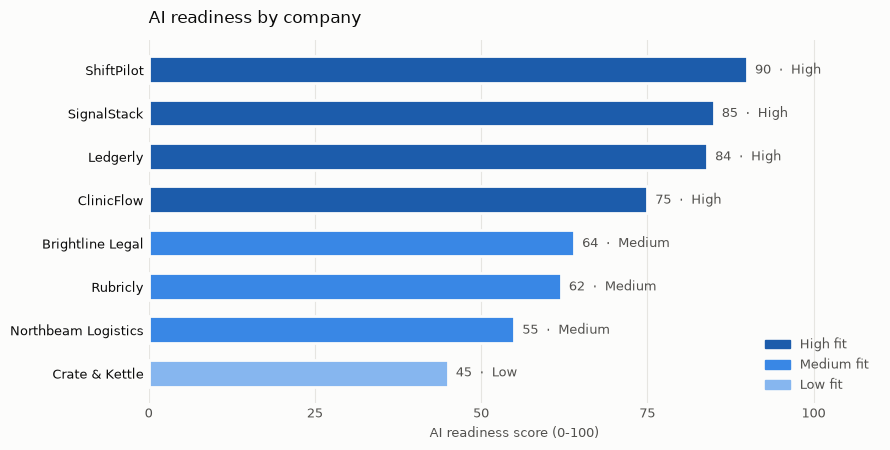

In [7]:
FIT_ORDER = ["High", "Medium", "Low"]
FIT_COLORS = {"High": "#1c5cab", "Medium": "#3987e5", "Low": "#86b6ef"}  # one blue hue, ordinal ramp
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

plot_df = df.sort_values("aiReadinessScore")  # largest bar at the top
fig, ax = plt.subplots(figsize=(9, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

bars = ax.barh(
    plot_df["companyName"], plot_df["aiReadinessScore"],
    color=[FIT_COLORS[f] for f in plot_df["acquisitionFit"]],
    height=0.62, edgecolor=SURFACE, linewidth=2,
)
for bar, score, fit in zip(bars, plot_df["aiReadinessScore"], plot_df["acquisitionFit"]):
    ax.text(bar.get_width() + 1.2, bar.get_y() + bar.get_height() / 2,
            f"{score}  ·  {fit}", va="center", fontsize=9, color=INK_MUTED)

ax.set_xlim(0, 110)
ax.set_xticks(range(0, 101, 25))
ax.set_xlabel("AI readiness score (0-100)", color=INK_MUTED, fontsize=9)
ax.tick_params(colors=INK_MUTED, labelsize=9, length=0)
ax.tick_params(axis="y", colors=INK)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=FIT_COLORS[f]) for f in FIT_ORDER]
ax.legend(handles, [f"{f} fit" for f in FIT_ORDER], loc="lower right", frameon=False,
          fontsize=9, labelcolor=INK_MUTED)
ax.set_title("AI readiness by company", loc="left", fontsize=12, color=INK, pad=12)
plt.tight_layout()
plt.show()

## 5. Filtering, as the dashboard does

The dashboard's fit filter and score sort, done in pandas.

In [8]:
print("Leads per acquisition fit:")
print(df["acquisitionFit"].value_counts().reindex(FIT_ORDER, fill_value=0).to_string())

high_fit = df[df["acquisitionFit"] == "High"]
print(f"\nHigh-fit targets ({len(high_fit)}), ranked:")
high_fit[["companyName", "aiReadinessScore", "aiTransformationAngle"]]

Leads per acquisition fit:
acquisitionFit
High      4
Medium    3
Low       1

High-fit targets (4), ranked:


,companyName,aiReadinessScore,aiTransformationAngle
0,ShiftPilot,90,Embedding AI copilots into the core workflows of ShiftPilot could automate manual operations and unlock margin expan...
1,SignalStack,85,Embedding AI copilots into the core workflows of SignalStack could automate manual operations and unlock margin expa...
2,Ledgerly,84,Embedding AI copilots into the core workflows of Ledgerly could automate manual operations and unlock margin expansi...
3,ClinicFlow,75,Embedding AI copilots into the core workflows of ClinicFlow could automate manual operations and unlock margin expan...


### Growth bottlenecks, expanded

One row per bottleneck, useful for spotting themes that repeat across the portfolio.

In [9]:
bottlenecks = (
    df[["companyName", "acquisitionFit", "growthBottlenecks"]]
    .explode("growthBottlenecks")
    .rename(columns={"growthBottlenecks": "bottleneck"})
    .reset_index(drop=True)
)
bottlenecks

,companyName,acquisitionFit,bottleneck
0,ShiftPilot,High,Limited product-led growth motion and self-serve funnel
1,ShiftPilot,High,Churn concentrated in SMB segment with weak retention tooling
2,ShiftPilot,High,Narrow integration ecosystem limits enterprise adoption
3,SignalStack,High,Fragmented customer data across disconnected tools
4,SignalStack,High,Pricing not aligned to usage or value delivered
5,SignalStack,High,Reporting relies on spreadsheets rather than embedded analytics
6,Ledgerly,High,"Manual, sales-led onboarding limits expansion velocity"
7,Ledgerly,High,Limited product-led growth motion and self-serve funnel
8,Ledgerly,High,Churn concentrated in SMB segment with weak retention tooling
9,ClinicFlow,High,Fragmented customer data across disconnected tools


## 6. Live AI vs. fallback

Each lead is analyzed independently. If the OpenAI call fails for one company (no key, timeout, rate limit, exhausted credits, or malformed output), **only that lead** falls back to a deterministic heuristic. The batch still succeeds with HTTP 200.
`fallbackReason` records why.

In [10]:
source_counts = df["enrichmentSource"].value_counts()
print(source_counts.to_string(), "\n")

if "fallbackReason" in df.columns and df["fallbackReason"].notna().any():
    print("Fallback reasons:")
    for reason, n in df["fallbackReason"].dropna().value_counts().items():
        print(f"  [{n}x] {reason}")
else:
    print("All leads were analyzed by the live model.")

enrichmentSource
fallback    8 

Fallback reasons:
  [8x] 429 You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.


## 7. Alternate payload shape

The endpoint also accepts `{ "leads": [...] }`. A lead without an `id` is assigned a UUID.

In [11]:
resp = requests.post(
    f"{API_URL}/api/enrich-leads",
    json={"leads": [{"companyName": "Quillbase", "industry": "Developer tools SaaS", "employeeCount": 60}]},
    timeout=TIMEOUT,
)
lead = resp.json()["leads"][0]
print(f"HTTP {resp.status_code}")
print({k: lead[k] for k in ["id", "companyName", "aiReadinessScore", "acquisitionFit", "enrichmentSource"]})

HTTP 200
{'id': '2109f2e9-f844-4375-b80c-e640eb2e8977', 'companyName': 'Quillbase', 'aiReadinessScore': 76, 'acquisitionFit': 'High', 'enrichmentSource': 'fallback'}


## 8. Error handling

Invalid requests are rejected *before* any OpenAI call is made. Every error uses the same shape:
`{ "error": { "code", "message", "details?" } }`.

In [12]:
cases = {
    "Empty array":            dict(json=[]),
    "Not an array":           dict(json={"foo": "bar"}),
    "Missing companyName":    dict(json=[{"companyName": "Valid Co"}, {"industry": "SaaS"}]),
    "Malformed JSON":         dict(data="{not json", headers={"Content-Type": "application/json"}),
    "Too many leads (51)":    dict(json=[{"companyName": f"Co {i}"} for i in range(51)]),
}

rows = []
for name, kwargs in cases.items():
    r = requests.post(f"{API_URL}/api/enrich-leads", timeout=30, **kwargs)
    err = r.json().get("error", {})
    rows.append({"case": name, "status": r.status_code, "code": err.get("code"),
                 "message": err.get("message"), "details": err.get("details")})

r = requests.get(f"{API_URL}/api/does-not-exist", timeout=10)
rows.append({"case": "Unknown route", "status": r.status_code, "code": r.json()["error"]["code"],
             "message": r.json()["error"]["message"], "details": None})

pd.DataFrame(rows)

,case,status,code,message,details
0,Empty array,400,EMPTY_PAYLOAD,At least one lead is required.,None
1,Not an array,400,INVALID_PAYLOAD,"Expected an array of leads (or an object with a ""leads"" array).",None
2,Missing companyName,422,VALIDATION_FAILED,One or more leads are invalid.,"[{'index': 1, 'message': '""companyName"" is required.'}]"
3,Malformed JSON,400,INVALID_JSON,Request body is not valid JSON.,None
4,Too many leads (51),413,TOO_MANY_LEADS,A maximum of 50 leads can be enriched per request.,None
5,Unknown route,404,NOT_FOUND,Route GET /api/does-not-exist not found,None


## Summary

- `GET /api/health` reports server status and whether live AI is configured.
- `POST /api/enrich-leads` turns raw company records into AI readiness scores, acquisition fit, growth bottlenecks and an AI transformation thesis.
- Model output is validated (score clamped to 0-100, fit checked against the allowed values, required fields present) before it is accepted.
- AI failures degrade **per lead** to a deterministic heuristic, flagged by `enrichmentSource: "fallback"` and `fallbackReason`, so the batch never fails as a whole.
- Bad input gets clear 4xx errors and never reaches OpenAI.

For the visual version of this flow, open the dashboard at **http://localhost:3000/leads** and click **Run AI Enrichment**.